In [1]:
from pathlib import Path
import math
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
elif not (repo_root / "data").exists() and (repo_root.parent / "data").exists():
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root))

from utils.calculations import arpu, ltv, ltv_cac, user_bases, annual_profit, npv, sensitivity_npv

cfg = json.loads((repo_root / "data" / "task_03_ai_pricing_config.json").read_text(encoding="utf-8"))
figures_dir = repo_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
def opening_fmt_int(value):
    return f"{value:,.0f}".replace(",", " ")


task_opening = f"""# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №{cfg['task_id']}: {cfg['title']}

**Дата:** {cfg['date']}  
**Студент:** {cfg['student']}  
**Группа:** {cfg['group']}  
**Проект:** «{cfg['project_name']}»

## Экономическая постановка задачи

Проект «{cfg['project_name']}» представляет AI-сервис по созданию контента. Необходимо сравнить четыре ценовые стратегии — Freemium, подписку, динамическое и персонализированное ценообразование — и выбрать вариант, который обеспечивает наилучший экономический результат.

В рамках решения требуется рассчитать ARPU, LTV, LTV/CAC, прогнозную прибыль и NPV за заданный горизонт, выполнить анализ чувствительности к изменению конверсии, churn и CAC, выбрать стратегию, разработать план внедрения и определить основные риски.

Потенциальный рынок составляет {opening_fmt_int(cfg['market_potential_users'])} пользователей, начальная база — {opening_fmt_int(cfg['initial_users'])}. Затраты на разработку, поддержание, тарифы, конверсия, churn, темпы роста и CAC загружаются из JSON-конфигурации ниже и используются во всех расчётах.
"""
display(Markdown(task_opening))
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " ").replace(".", ","))
print(f"Проект: {cfg['project_name']}")
print(f"Период расчёта: {cfg['horizon_years']} года; ставка дисконтирования: {cfg['annual_discount_rate']:.0%}")

# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №3: Выбор ценовой стратегии для AI-сервиса по созданию контента

**Дата:** 02.09.2026  
**Студент:** Глазков Тимофей Владимирович  
**Группа:** БИ ОЗФО5-1  
**Проект:** «AI-Копирайтер»

## Экономическая постановка задачи

Проект «AI-Копирайтер» представляет AI-сервис по созданию контента. Необходимо сравнить четыре ценовые стратегии — Freemium, подписку, динамическое и персонализированное ценообразование — и выбрать вариант, который обеспечивает наилучший экономический результат.

В рамках решения требуется рассчитать ARPU, LTV, LTV/CAC, прогнозную прибыль и NPV за заданный горизонт, выполнить анализ чувствительности к изменению конверсии, churn и CAC, выбрать стратегию, разработать план внедрения и определить основные риски.

Потенциальный рынок составляет 500 000 пользователей, начальная база — 1 000. Затраты на разработку, поддержание, тарифы, конверсия, churn, темпы роста и CAC загружаются из JSON-конфигурации ниже и используются во всех расчётах.


Проект: AI-Копирайтер
Период расчёта: 3 года; ставка дисконтирования: 12%


## Исходные данные задачи
Все числовые параметры и характеристики стратегий выводятся из JSON-конфигурации. Это позволяет менять исходные данные без редактирования текста Notebook.


In [2]:
def fmt_pct(value, digits=0):
    return f"{value:.{digits}%}".replace(".", ",")

def fmt_int(value):
    return f"{value:,.0f}".replace(",", " ")

source_table = pd.DataFrame([
    ["Потенциальный рынок", f"{fmt_int(cfg['market_potential_users'])} пользователей"],
    ["Рост рынка", fmt_pct(cfg['market_growth_annual']) + " в год"],
    ["Разработка", f"{fmt_int(cfg['development_cost_rub'])} руб."],
    ["Поддержание", f"{fmt_int(cfg['monthly_maintenance_cost_rub'])} руб./мес."],
    ["Начальная база", f"{fmt_int(cfg['initial_users'])} пользователей"],
    ["Ставка дисконтирования", fmt_pct(cfg['annual_discount_rate']) + " годовых"],
    ["Горизонт", f"{cfg['horizon_years']} года"],
], columns=["Показатель", "Значение"])
display(source_table)
strategy_input = pd.DataFrame([
    [name, values["price_rub_month"], values["conversion"], values["churn"]]
    for name, values in cfg["strategies"].items()
], columns=["Стратегия", "Цена, руб./мес.", "Конверсия", "Churn"])
display(strategy_input)
cac_table = pd.DataFrame(list(cfg["cac_channels_rub"].items()), columns=["Канал привлечения", "CAC, руб."])
display(cac_table)


,Показатель,Значение
0,Потенциальный рынок,500 000 пользователей
1,Рост рынка,25% в год
2,Разработка,15 000 000 руб.
3,Поддержание,2 000 000 руб./мес.
4,Начальная база,1 000 пользователей
5,Ставка дисконтирования,12% годовых
6,Горизонт,3 года


,Стратегия,"Цена, руб./мес.",Конверсия,Churn
0,Freemium,2000,"0,02","0,08"
1,Подписка,1500,"0,20","0,05"
2,Динамическая,1200,"0,15","0,06"
3,Персонализированная,1500,"0,12","0,04"


,Канал привлечения,"CAC, руб."
0,Реклама,1500
1,Контент-маркетинг,800
2,Виральный рост,100


# Часть 1. Расчёт ключевых метрик

## Вопрос 1. Рассчитать ARPU для каждой стратегии

**Формула:**

$$ARPU = Цена \times Конверсия.$$

ARPU показывает ожидаемый средний месячный доход на одного пользователя с учётом доли пользователей, которые переходят на платный вариант.

In [3]:
arpu_table = pd.DataFrame([
    [name, values["price_rub_month"], values["conversion"], arpu(values["price_rub_month"], values["conversion"])]
    for name, values in cfg["strategies"].items()
], columns=["Стратегия", "Цена, руб./мес.", "Конверсия", "ARPU, руб./мес."])
display(arpu_table)
best_arpu = arpu_table.loc[arpu_table["ARPU, руб./мес."].idxmax()]
print(f"Ответ на вопрос 1: максимальный ARPU имеет стратегия «{best_arpu['Стратегия']}» — {best_arpu['ARPU, руб./мес.']:.0f} руб./мес.")

,Стратегия,"Цена, руб./мес.",Конверсия,"ARPU, руб./мес."
0,Freemium,2000,"0,02","40,00"
1,Подписка,1500,"0,20","300,00"
2,Динамическая,1200,"0,15","180,00"
3,Персонализированная,1500,"0,12","180,00"


Ответ на вопрос 1: максимальный ARPU имеет стратегия «Подписка» — 300 руб./мес.


## Вопрос 2. Рассчитать LTV для каждой стратегии

**Формула:**

$$LTV = \frac{ARPU}{Churn}.$$

Средний срок жизни клиента определяется как $1 / Churn$. Чем ниже churn, тем дольше сохраняется клиент и тем выше его LTV при прочих равных условиях.

In [4]:
ltv_table = pd.DataFrame([
    [name, arpu(values["price_rub_month"], values["conversion"]), values["churn"], 1 / values["churn"], ltv(arpu(values["price_rub_month"], values["conversion"]), values["churn"])]
    for name, values in cfg["strategies"].items()
], columns=["Стратегия", "ARPU, руб./мес.", "Churn", "Срок жизни, мес.", "LTV, руб."])
display(ltv_table)
best_ltv = ltv_table.loc[ltv_table["LTV, руб."].idxmax()]
print(f"Ответ на вопрос 2: максимальный LTV имеет стратегия «{best_ltv['Стратегия']}» — {best_ltv['LTV, руб.']:.0f} руб.")

,Стратегия,"ARPU, руб./мес.",Churn,"Срок жизни, мес.","LTV, руб."
0,Freemium,"40,00","0,08","12,50","500,00"
1,Подписка,"300,00","0,05","20,00","6 000,00"
2,Динамическая,"180,00","0,06","16,67","3 000,00"
3,Персонализированная,"180,00","0,04","25,00","4 500,00"


Ответ на вопрос 2: максимальный LTV имеет стратегия «Подписка» — 6000 руб.


## Вопрос 3. Рассчитать LTV/CAC для каналов привлечения

**Формула:**

$$LTV/CAC = \frac{LTV}{CAC}.$$

Расчёт выполнен отдельно для рекламы, контент-маркетинга и вирального роста.

In [5]:
ltv_cac_rows = []
for name, values in cfg["strategies"].items():
    strategy_ltv = ltv(arpu(values["price_rub_month"], values["conversion"]), values["churn"])
    ltv_cac_rows.append([name, strategy_ltv] + [ltv_cac(strategy_ltv, cac) for cac in cfg["cac_channels_rub"].values()])
ltv_cac_table = pd.DataFrame(ltv_cac_rows, columns=["Стратегия", "LTV, руб.", "Реклама", "Контент-маркетинг", "Виральный рост"])
for col in ["Реклама", "Контент-маркетинг", "Виральный рост"]:
    ltv_cac_table[col] = ltv_cac_table[col].map(lambda x: f"{x:.2f}x".replace(".", ","))
display(ltv_cac_table)
ltv_cac_wide = ltv_cac_table.set_index("Стратегия")[["Реклама", "Контент-маркетинг", "Виральный рост"]].T
ltv_cac_wide.index.name = "Канал привлечения"
display(ltv_cac_wide)
numeric_ltv_cac = pd.DataFrame(ltv_cac_rows, columns=["Стратегия", "LTV, руб.", "Реклама", "Контент-маркетинг", "Виральный рост"])
best_channel = numeric_ltv_cac[["Реклама", "Контент-маркетинг", "Виральный рост"]].max().idxmax()
best_channel_value = numeric_ltv_cac[best_channel].max()
best_channel_strategy = numeric_ltv_cac.loc[numeric_ltv_cac[best_channel].idxmax(), "Стратегия"]
print(f"Ответ на вопрос 3: максимальное LTV/CAC даёт канал «{best_channel}» для стратегии «{best_channel_strategy}» — {best_channel_value:.2f}x.")

,Стратегия,"LTV, руб.",Реклама,Контент-маркетинг,Виральный рост
0,Freemium,"500,00","0,33x","0,62x","5,00x"
1,Подписка,"6 000,00","4,00x","7,50x","60,00x"
2,Динамическая,"3 000,00","2,00x","3,75x","30,00x"
3,Персонализированная,"4 500,00","3,00x","5,62x","45,00x"


Стратегия,Freemium,Подписка,Динамическая,Персонализированная
Канал привлечения,,,,
Реклама,"0,33x","4,00x","2,00x","3,00x"
Контент-маркетинг,"0,62x","7,50x","3,75x","5,62x"
Виральный рост,"5,00x","60,00x","30,00x","45,00x"


Ответ на вопрос 3: максимальное LTV/CAC даёт канал «Виральный рост» для стратегии «Подписка» — 60.00x.


# Часть 2. Оценка эффективности
## Вопрос 4. Рассчитать прогнозную прибыль за заданный горизонт
Модель роста базы пользователей и канал CAC берутся из JSON. Для каждого года рассчитывается доход, поддержание, стоимость привлечения новых пользователей и прибыль.

Прибыль за период рассчитывается как:
$$П_t = ARPU \times N_t \times 12 - Затраты_{поддержания,t} - CAC \times \Delta N_t.$$

Затраты на разработку относятся к нулевому году и отдельно учитываются в NPV.

In [6]:
bases = user_bases(cfg["initial_users"], cfg["growth_rates"])
base_cac_channel = cfg["base_profit_cac_channel"]
base_cac = cfg["cac_channels_rub"][base_cac_channel]
profit_rows = []
for name, values in cfg["strategies"].items():
    strategy_arpu = arpu(values["price_rub_month"], values["conversion"])
    previous = bases[0]
    for year in range(1, len(bases)):
        current = bases[year]
        revenue = strategy_arpu * current * 12
        maintenance = cfg["monthly_maintenance_cost_rub"] * 12
        acquisition = (current - previous) * base_cac
        profit = revenue - maintenance - acquisition
        profit_rows.append([name, year, current, current - previous, revenue, maintenance, acquisition, profit])
        previous = current
profit_table = pd.DataFrame(profit_rows, columns=["Стратегия", "Год", "База", "Новые пользователи", "Доход, руб.", "Поддержание, руб.", "CAC, руб.", "Прибыль, руб."])
display(profit_table)
profit_summary = profit_table.groupby("Стратегия")["Прибыль, руб."].sum().sort_values(ascending=False)
best_profit_strategy = profit_summary.index[0]
positive_profit = profit_summary[profit_summary >= 0]
profit_conclusion = (f"положительную суммарную прибыль имеют: {', '.join(positive_profit.index)}"
                     if len(positive_profit) else "ни одна стратегия не имеет положительной суммарной прибыли")
print(f"Ответ на вопрос 4: лучший результат по суммарной прибыли показывает «{best_profit_strategy}» ({profit_summary.iloc[0]:,.0f} руб.); {profit_conclusion}.")

,Стратегия,Год,База,Новые пользователи,"Доход, руб.","Поддержание, руб.","CAC, руб.","Прибыль, руб."
0,Freemium,1,"2 000,00","1 000,00","960 000,00",24000000,"800 000,00","-23 840 000,00"
1,Freemium,2,"3 000,00","1 000,00","1 440 000,00",24000000,"800 000,00","-23 360 000,00"
2,Freemium,3,"3 600,00","600,00","1 728 000,00",24000000,"480 000,00","-22 752 000,00"
3,Подписка,1,"2 000,00","1 000,00","7 200 000,00",24000000,"800 000,00","-17 600 000,00"
4,Подписка,2,"3 000,00","1 000,00","10 800 000,00",24000000,"800 000,00","-14 000 000,00"
5,Подписка,3,"3 600,00","600,00","12 960 000,00",24000000,"480 000,00","-11 520 000,00"
6,Динамическая,1,"2 000,00","1 000,00","4 320 000,00",24000000,"800 000,00","-20 480 000,00"
7,Динамическая,2,"3 000,00","1 000,00","6 480 000,00",24000000,"800 000,00","-18 320 000,00"
8,Динамическая,3,"3 600,00","600,00","7 776 000,00",24000000,"480 000,00","-16 704 000,00"
9,Персонализированная,1,"2 000,00","1 000,00","4 320 000,00",24000000,"800 000,00","-20 480 000,00"


Ответ на вопрос 4: лучший результат по суммарной прибыли показывает «Подписка» (-43,120,000 руб.); ни одна стратегия не имеет положительной суммарной прибыли.


## Вопрос 5. Рассчитать NPV за заданный горизонт
**Формула:**
$$NPV = \sum_{t=0}^{T} \frac{CF_t}{(1+r)^t}.$$
В нулевом году отражаются затраты на разработку. Далее дисконтируются рассчитанные денежные потоки по годам горизонта.

In [7]:
npv_rows = []
for name, values in cfg["strategies"].items():
    strategy_arpu = arpu(values["price_rub_month"], values["conversion"])
    cash_flows = [-cfg["development_cost_rub"]]
    previous = bases[0]
    for year in range(1, len(bases)):
        current = bases[year]
        cash_flows.append(annual_profit(current, current - previous, strategy_arpu, cfg["monthly_maintenance_cost_rub"], base_cac))
        previous = current
    value = npv(cash_flows, cfg["annual_discount_rate"])
    npv_rows.append([name, *cash_flows, value, value / 1e6])
npv_table = pd.DataFrame(npv_rows, columns=["Стратегия", "Денежный поток, год 0, руб.", "Денежный поток, год 1, руб.", "Денежный поток, год 2, руб.", "Денежный поток, год 3, руб.", "NPV, руб.", "NPV, млн руб."])
display(npv_table)

best_npv = npv_table.loc[npv_table["NPV, млн руб."].idxmax()]
positive_npv = npv_table.loc[npv_table["NPV, млн руб."] >= 0, "Стратегия"].tolist()
npv_conclusion = f"положительный NPV имеют: {', '.join(positive_npv)}" if positive_npv else "положительного NPV нет ни у одной стратегии"
print(f"Ответ на вопрос 5: лучший NPV имеет «{best_npv['Стратегия']}» — {best_npv['NPV, млн руб.']:.2f} млн руб.; {npv_conclusion}.")

,Стратегия,"Денежный поток, год 0, руб.","Денежный поток, год 1, руб.","Денежный поток, год 2, руб.","Денежный поток, год 3, руб.","NPV, руб.","NPV, млн руб."
0,Freemium,-15000000,"-23 840 000,00","-23 360 000,00","-22 752 000,00","-71 102 587,46","-71,10"
1,Подписка,-15000000,"-17 600 000,00","-14 000 000,00","-11 520 000,00","-50 074 708,45","-50,07"
2,Динамическая,-15000000,"-20 480 000,00","-18 320 000,00","-16 704 000,00","-59 779 883,38","-59,78"
3,Персонализированная,-15000000,"-20 480 000,00","-18 320 000,00","-16 704 000,00","-59 779 883,38","-59,78"


Ответ на вопрос 5: лучший NPV имеет «Подписка» — -50.07 млн руб.; положительного NPV нет ни у одной стратегии.


# Часть 3. Анализ чувствительности

## Вопрос 6. Изменить конверсию, Churn и CAC на ±30%

Для удобства сравнения сценарии расположены строками, а стратегии — столбцами. Значения показаны в млн руб. При изменении конверсии изменяется ARPU. При изменении CAC меняются затраты на новых пользователей. При изменении Churn применяется отдельное годовое приближение удержания: доход масштабируется пропорционально изменению доли удержанных клиентов. Базовый сценарий при этом совпадает с основной моделью.

In [8]:
scenario_definitions = [
    ("Базовый сценарий", {}),
    ("Конверсия +30%", {"conversion_multiplier": 1.3}),
    ("Конверсия -30%", {"conversion_multiplier": 0.7}),
    ("Churn +30%", {"churn_multiplier": 1.3}),
    ("Churn -30%", {"churn_multiplier": 0.7}),
    ("CAC +30%", {"cac_multiplier": 1.3}),
    ("CAC -30%", {"cac_multiplier": 0.7}),
]
sensitivity_wide = []
for label, kwargs in scenario_definitions:
    row = {"Сценарий": label}
    for name, values in cfg["strategies"].items():
        row[name] = sensitivity_npv(values, bases, cfg["growth_rates"], cfg["monthly_maintenance_cost_rub"], base_cac, cfg["development_cost_rub"], cfg["annual_discount_rate"], **kwargs) / 1e6
    sensitivity_wide.append(row)
sensitivity_wide_table = pd.DataFrame(sensitivity_wide)
display(sensitivity_wide_table)
selected_sensitivity_strategy = best_npv["Стратегия"]
selected_sensitivity = sensitivity_wide_table[["Сценарий", selected_sensitivity_strategy]].copy()
selected_sensitivity["Отклонение от базового, млн руб."] = selected_sensitivity[selected_sensitivity_strategy] - selected_sensitivity.loc[selected_sensitivity["Сценарий"] == "Базовый сценарий", selected_sensitivity_strategy].iloc[0]
selected_sensitivity = selected_sensitivity.rename(columns={selected_sensitivity_strategy: f"NPV стратегии «{selected_sensitivity_strategy}», млн руб."})
display(Markdown(f"**Динамическая детализация:** стратегия «{selected_sensitivity_strategy}», выбранная по максимальному NPV."))
display(selected_sensitivity)
best_by_scenario = sensitivity_wide_table.set_index("Сценарий").idxmax(axis=1)
best_counts = best_by_scenario.value_counts()
overall_sensitivity_winner = best_counts.index[0]
print(f"Ответ на вопрос 6: лучший NPV чаще всего показывает «{overall_sensitivity_winner}» ({best_counts.iloc[0]} из {len(best_by_scenario)} сценариев).")

,Сценарий,Freemium,Подписка,Динамическая,Персонализированная
0,Базовый сценарий,"-71,10","-50,07","-59,78","-59,78"
1,Конверсия +30%,"-70,13","-42,80","-55,41","-55,41"
2,Конверсия -30%,"-72,07","-57,35","-64,15","-64,15"
3,Churn +30%,"-71,19","-50,46","-60,06","-59,96"
4,Churn -30%,"-71,02","-49,69","-59,50","-59,60"
5,CAC +30%,"-71,61","-50,58","-60,29","-60,29"
6,CAC -30%,"-70,59","-49,57","-59,27","-59,27"


**Динамическая детализация:** стратегия «Подписка», выбранная по максимальному NPV.

,Сценарий,"NPV стратегии «Подписка», млн руб.","Отклонение от базового, млн руб."
0,Базовый сценарий,"-50,07","0,00"
1,Конверсия +30%,"-42,80","7,28"
2,Конверсия -30%,"-57,35","-7,28"
3,Churn +30%,"-50,46","-0,38"
4,Churn -30%,"-49,69","0,38"
5,CAC +30%,"-50,58","-0,51"
6,CAC -30%,"-49,57","0,51"


Ответ на вопрос 6: лучший NPV чаще всего показывает «Подписка» (7 из 7 сценариев).


## Вопрос 7. Определить наиболее устойчивую стратегию

Устойчивость оценивается по размаху NPV между минимальным и максимальным сценарием. Чем меньше размах, тем слабее чувствительность к изменению параметров.

In [9]:
sensitivity_long = sensitivity_wide_table.melt(id_vars="Сценарий", var_name="Стратегия", value_name="NPV, млн руб.")
stability = sensitivity_long.groupby("Стратегия")["NPV, млн руб."].agg(["min", "max"])
stability["Размах NPV, млн руб."] = stability["max"] - stability["min"]
stability = stability.sort_values("Размах NPV, млн руб.").reset_index()
display(stability)
most_stable = stability.iloc[0]
selected_stability = stability.loc[stability["Стратегия"] == best_npv["Стратегия"]].iloc[0]
print(f"Ответ на вопрос 7: по абсолютному размаху наиболее стабильна «{most_stable['Стратегия']}» — {most_stable['Размах NPV, млн руб.']:.2f} млн руб.")
print(f"Для выбранной стратегии «{best_npv['Стратегия']}» размах NPV составляет {selected_stability['Размах NPV, млн руб.']:.2f} млн руб.; именно её чувствительность дополнительно показана в таблице сценариев.")

,Стратегия,min,max,"Размах NPV, млн руб."
0,Freemium,"-72,07","-70,13","1,94"
1,Динамическая,"-64,15","-55,41","8,73"
2,Персонализированная,"-64,15","-55,41","8,73"
3,Подписка,"-57,35","-42,80","14,56"


Ответ на вопрос 7: по абсолютному размаху наиболее стабильна «Freemium» — 1.94 млн руб.
Для выбранной стратегии «Подписка» размах NPV составляет 14.56 млн руб.; именно её чувствительность дополнительно показана в таблице сценариев.


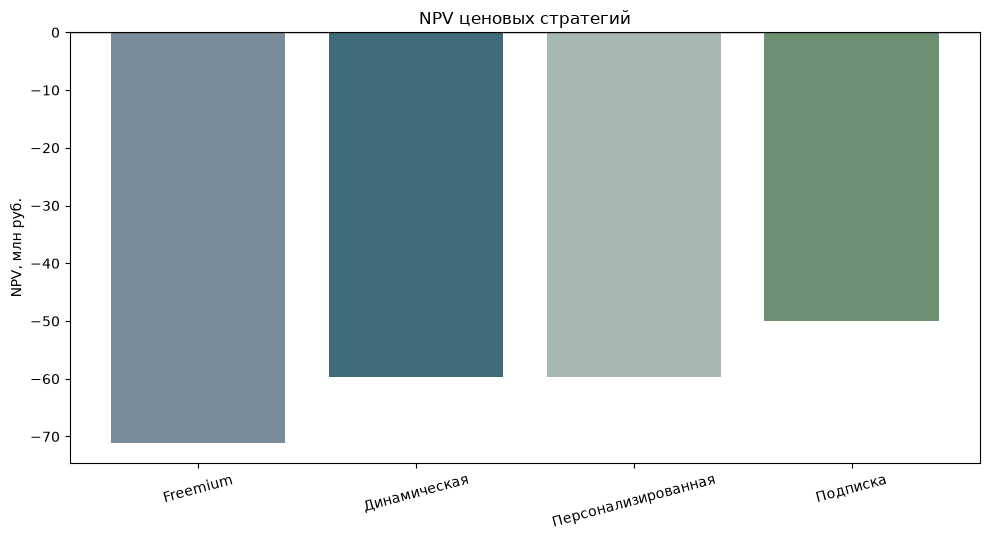

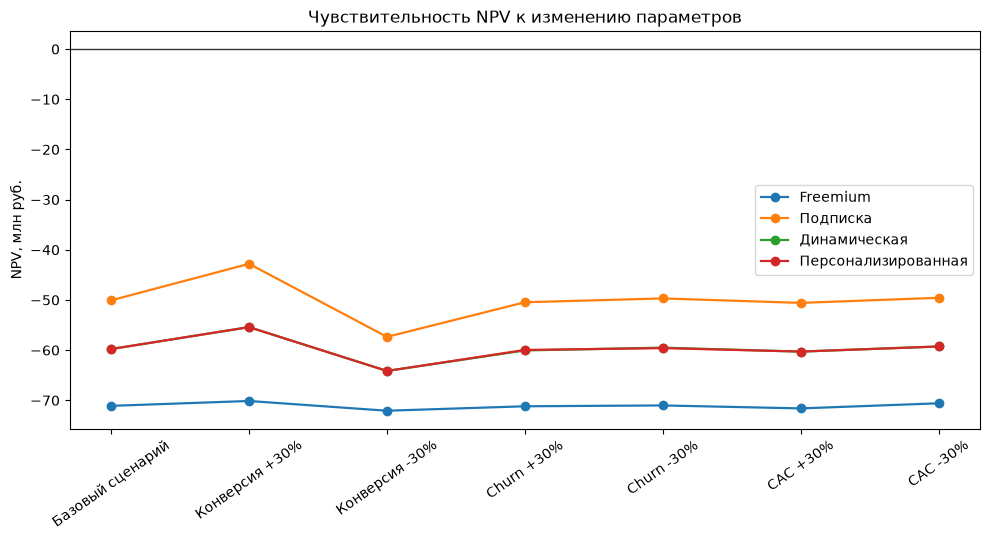

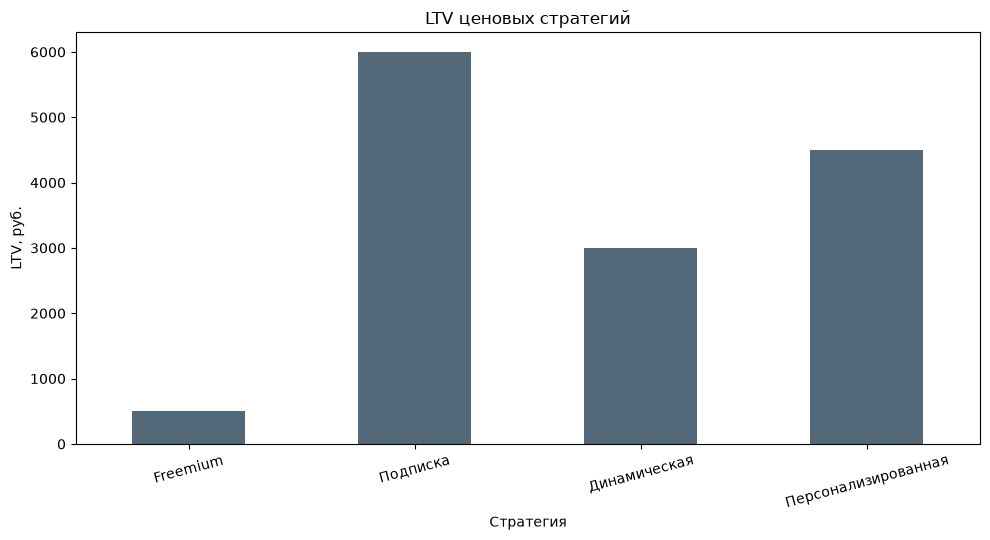

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.5))
npv_plot = npv_table.sort_values("NPV, млн руб.")
ax.bar(npv_plot["Стратегия"], npv_plot["NPV, млн руб."], color=["#7A8B99", "#3F6B7A", "#A6B8B0", "#6F8F72"])
ax.axhline(0, color="#333333", linewidth=1)
ax.set_title("NPV ценовых стратегий")
ax.set_ylabel("NPV, млн руб.")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(figures_dir / "task_03_npv_by_strategy.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5.5))
for strategy in cfg["strategies"]:
    subset = sensitivity_long[sensitivity_long["Стратегия"] == strategy]
    ax.plot(subset["Сценарий"], subset["NPV, млн руб."], marker="o", linewidth=1.6, label=strategy)
ax.axhline(0, color="#333333", linewidth=1)
ax.set_title("Чувствительность NPV к изменению параметров")
ax.set_ylabel("NPV, млн руб.")
ax.tick_params(axis="x", rotation=35)
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / "task_03_sensitivity.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5.5))
ltv_plot = ltv_table.set_index("Стратегия")["LTV, руб."]
ltv_plot.plot(kind="bar", ax=ax, color="#536878")
ax.set_title("LTV ценовых стратегий")
ax.set_ylabel("LTV, руб.")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(figures_dir / "task_03_ltv.png", dpi=160, bbox_inches="tight")
plt.show()

# Часть 4. Стратегические рекомендации

## Вопрос 8. Выбрать оптимальную ценовую стратегию

Рекомендация определяется по рассчитанным метрикам: сначала сравнивается NPV, затем ARPU, LTV и LTV/CAC. Если финансовые результаты отрицательны у всех стратегий, выбирается вариант с максимальным NPV и дополнительно проверяются его ARPU, LTV и устойчивость.

In [11]:
selection_rows = []
for name, values in cfg["strategies"].items():
    strategy_arpu = arpu(values["price_rub_month"], values["conversion"])
    strategy_ltv = ltv(strategy_arpu, values["churn"])
    strategy_npv = npv_table.loc[npv_table["Стратегия"] == name, "NPV, млн руб."].iloc[0]
    strategy_ratio = strategy_ltv / base_cac
    selection_rows.append([name, strategy_arpu, strategy_ltv, strategy_ratio, strategy_npv])
selection_table = pd.DataFrame(selection_rows, columns=["Стратегия", "ARPU, руб./мес.", "LTV, руб.", "LTV/CAC: контент", "NPV, млн руб."])
selection_table["Решение"] = np.where(selection_table["Стратегия"] == best_npv["Стратегия"], "Рекомендуется", "Альтернативный вариант")
display(selection_table)
selected_metrics = selection_table.loc[selection_table["Стратегия"] == best_npv["Стратегия"]].iloc[0]
if best_npv['NPV, млн руб.'] >= 0:
    decision_text = f"стратегия «{best_npv['Стратегия']}» рекомендуется к запуску"
else:
    decision_text = f"стратегия «{best_npv['Стратегия']}» является лучшей альтернативой, но запуск не рекомендуется без улучшения экономики проекта"
print(f"Ответ на вопрос 8: {decision_text}. Максимальный NPV = {best_npv['NPV, млн руб.']:.2f} млн руб.")
print(f"Её ARPU = {selected_metrics['ARPU, руб./мес.']:.2f} руб./мес., LTV = {selected_metrics['LTV, руб.']:.2f} руб., LTV/CAC = {selected_metrics['LTV/CAC: контент']:.2f}x.")

,Стратегия,"ARPU, руб./мес.","LTV, руб.",LTV/CAC: контент,"NPV, млн руб.",Решение
0,Freemium,"40,00","500,00","0,62","-71,10",Альтернативный вариант
1,Подписка,"300,00","6 000,00","7,50","-50,07",Рекомендуется
2,Динамическая,"180,00","3 000,00","3,75","-59,78",Альтернативный вариант
3,Персонализированная,"180,00","4 500,00","5,62","-59,78",Альтернативный вариант


Ответ на вопрос 8: стратегия «Подписка» является лучшей альтернативой, но запуск не рекомендуется без улучшения экономики проекта. Максимальный NPV = -50.07 млн руб.
Её ARPU = 300.00 руб./мес., LTV = 6000.00 руб., LTV/CAC = 7.50x.


## Вопрос 9. Разработать план внедрения выбранной стратегии

| Период | План действий |
|---|---|
| Год 1. Выход на рынок | Запуск выбранной стратегии с 14-дневным пробным периодом; контент-маркетинг; интеграции с Tilda и WordPress. |
| Год 2. Рост | Реферальная программа; функции для отдельных ниш; автоматизация воронки продаж. |
| Год 3. Зрелость | Снижение churn через улучшение продукта; сегментные тарифы; аналитические продукты. |

In [12]:
monitoring_table = pd.DataFrame([
    ["Churn Rate", "< 5%", "Ежемесячно"],
    ["LTV/CAC", "> 3x", "Ежеквартально"],
    ["MRR", "Рост 20% в месяц", "Ежемесячно"],
    ["Конверсия", "> 20%", "Ежемесячно"],
    ["NRR", "> 120%", "Ежеквартально"],
], columns=["Метрика", "Целевое значение", "Частота мониторинга"])
display(monitoring_table)
print(f"Ответ на вопрос 9: дорожная карта начинается со стратегии «{best_npv['Стратегия']}», далее используются пробный период, контент-маркетинг, реферальные механизмы и сегментация.")

,Метрика,Целевое значение,Частота мониторинга
0,Churn Rate,< 5%,Ежемесячно
1,LTV/CAC,> 3x,Ежеквартально
2,MRR,Рост 20% в месяц,Ежемесячно
3,Конверсия,> 20%,Ежемесячно
4,NRR,> 120%,Ежеквартально


Ответ на вопрос 9: дорожная карта начинается со стратегии «Подписка», далее используются пробный период, контент-маркетинг, реферальные механизмы и сегментация.


## Вопрос 10. Проанализировать риски и меры митигации

| Риск | Вероятность | Мера снижения |
|---|---|---|
| Рост churn | Средняя | Регулярный сбор обратной связи и улучшение продукта. |
| Снижение конверсии | Средняя | A/B-тестирование пробного периода и тарифов. |
| Рост CAC | Высокая | Диверсификация каналов, контент-маркетинг и реферальная программа. |
| Усиление конкуренции | Высокая | Развитие AI-модели и уникальных функций. |
| Регуляторные ограничения | Низкая | Юридическая проверка использования AI и контента. |

# Итоговый вывод и экономический анализ
Итоговая рекомендация и пороги улучшения рассчитываются по данным JSON. Нижний порог означает NPV = 0, а целевой верхний порог задаётся параметром `economic_analysis.target_npv_mln_rub`.
Пороговые значения рассчитываются изменением одного параметра за раз при сохранении остальных параметров модели.

In [13]:
print("Итоговый вывод")
if best_npv['NPV, млн руб.'] >= 0:
    print(f"Рекомендуемая стратегия: «{best_npv['Стратегия']}».")
else:
    print(f"Лучшая альтернатива: «{best_npv['Стратегия']}», но запуск не рекомендуется без улучшения экономики проекта.")
print(f"Критерий выбора: максимальный рассчитанный NPV = {best_npv['NPV, млн руб.']:.2f} млн руб.")
print(f"ARPU выбранной стратегии: {selected_metrics['ARPU, руб./мес.']:.2f} руб./мес.; LTV: {selected_metrics['LTV, руб.']:.2f} руб.; LTV/CAC: {selected_metrics['LTV/CAC: контент']:.2f}x.")
print(f"Наиболее устойчивая стратегия по размаху NPV: «{most_stable['Стратегия']}».")

# Экономический анализ: нижний порог — NPV = 0, целевой верхний порог — NPV из JSON.
analysis_cfg = cfg['economic_analysis']
selected_strategy_name = best_npv['Стратегия']
selected_strategy_cfg = cfg['strategies'][selected_strategy_name]
selected_arpu_base = arpu(selected_strategy_cfg['price_rub_month'], selected_strategy_cfg['conversion'])
targets_mln = [analysis_cfg['break_even_npv_mln_rub'], analysis_cfg['target_npv_mln_rub']]

def evaluate_project(arpu_value=selected_arpu_base, cac_value=base_cac, maintenance_value=cfg['monthly_maintenance_cost_rub'], development_value=cfg['development_cost_rub'], growth_multiplier=1.0):
    scenario_growth = [rate * growth_multiplier for rate in cfg['growth_rates']]
    scenario_bases = user_bases(cfg['initial_users'], scenario_growth)
    flows = [-development_value]
    previous = scenario_bases[0]
    for year in range(1, len(scenario_bases)):
        current = scenario_bases[year]
        flows.append(annual_profit(current, current - previous, arpu_value, maintenance_value, cac_value))
        previous = current
    return npv(flows, cfg['annual_discount_rate'])

def min_threshold(fn, target, start, high=None):
    low = float(start)
    high = float(high if high is not None else max(1.0, start * 2 + 1))
    while fn(high) < target and high < 1e9:
        high *= 2
    if fn(high) < target:
        return math.inf
    for _ in range(70):
        mid = (low + high) / 2
        if fn(mid) >= target: high = mid
        else: low = mid
    return high

def max_threshold(fn, target, low, high=None):
    low = float(low)
    if fn(low) < target: return math.nan
    high = float(high if high is not None else max(1.0, low * 2 + 1))
    while fn(high) >= target and high < 1e9:
        high *= 2
    if fn(high) >= target: return math.inf
    for _ in range(70):
        mid = (low + high) / 2
        if fn(mid) >= target: low = mid
        else: high = mid
    return low

def pct_change(new, old):
    return (new / old - 1) * 100 if old else math.nan

def fmt_threshold(value, unit):
    if math.isnan(value): return 'недостижимо'
    if math.isinf(value): return 'выше диапазона поиска'
    if unit == 'руб.': return f'{value:,.2f}'.replace(',', ' ').replace('.', ',') + ' руб.'
    if unit == '%': return f'{value:.2f}'.replace('.', ',') + '%'
    return f'{value:,.2f}'.replace(',', ' ').replace('.', ',') + ' ' + unit

analysis_rows = []
for target_mln in targets_mln:
    target = target_mln * 1_000_000
    arpu_req = min_threshold(lambda x: evaluate_project(arpu_value=x), target, 0.0, max(1.0, selected_arpu_base))
    cac_limit = max_threshold(lambda x: evaluate_project(cac_value=x), target, 0.0, max(1.0, base_cac))
    maint_limit = max_threshold(lambda x: evaluate_project(maintenance_value=x), target, 0.0, max(1.0, cfg['monthly_maintenance_cost_rub']))
    dev_limit = max_threshold(lambda x: evaluate_project(development_value=x), target, 0.0, max(1.0, cfg['development_cost_rub']))
    growth_multiplier = min_threshold(lambda x: evaluate_project(growth_multiplier=x), target, 0.0, 1.0)
    analysis_rows.append({
        'Порог NPV, млн руб.': target_mln,
        'Минимальный ARPU, руб./мес.': arpu_req,
        'Максимальный CAC, руб.': cac_limit,
        'Максимальное поддержание, руб./мес.': maint_limit,
        'Максимальная разработка, руб.': dev_limit,
        'Минимальный множитель роста': growth_multiplier,
        'Темп роста к текущему, %': growth_multiplier * 100,
        'Требуемые темпы роста по годам': ' / '.join(f'{rate * growth_multiplier:.2%}'.replace('.', ',') for rate in cfg['growth_rates']),
    })
economic_thresholds = pd.DataFrame(analysis_rows)
display(Markdown(f"### Экономический анализ стратегии «{selected_strategy_name}»"))
display(Markdown(f"Нижний порог — NPV = {analysis_cfg['break_even_npv_mln_rub']:.2f} млн руб.; целевой верхний порог — NPV = {analysis_cfg['target_npv_mln_rub']:.2f} млн руб. Расчёт изменяет по одному фактору за раз, остальные параметры сохраняются из JSON."))
# В итоговой таблице технические NaN заменяются понятным экономическим выводом.
economic_thresholds_display = economic_thresholds.copy()
rub_columns = ['Минимальный ARPU, руб./мес.', 'Максимальный CAC, руб.', 'Максимальное поддержание, руб./мес.', 'Максимальная разработка, руб.']
for column in rub_columns:
    economic_thresholds_display[column] = economic_thresholds_display[column].map(lambda value: fmt_threshold(value, 'руб.'))
economic_thresholds_display['Порог NPV, млн руб.'] = economic_thresholds_display['Порог NPV, млн руб.'].map(lambda value: f'{value:.2f}'.replace('.', ','))
economic_thresholds_display['Минимальный множитель роста'] = economic_thresholds_display['Минимальный множитель роста'].map(lambda value: fmt_threshold(value, 'x'))
economic_thresholds_display['Темп роста к текущему, %'] = economic_thresholds_display['Темп роста к текущему, %'].map(lambda value: fmt_threshold(value, '%'))
display(economic_thresholds_display)

base_arpu = selected_arpu_base
break_row = economic_thresholds.iloc[0]
target_row = economic_thresholds.iloc[1]

print("Что необходимо изменить:")
print(f"Нижний порог безубыточности: ARPU не ниже {fmt_threshold(break_row['Минимальный ARPU, руб./мес.'], 'руб.')}; CAC не выше {fmt_threshold(break_row['Максимальный CAC, руб.'], 'руб.')}; поддержание не выше {fmt_threshold(break_row['Максимальное поддержание, руб./мес.'], 'руб.')}; рост должен быть не ниже {break_row['Темп роста к текущему, %']:.2f}% от текущей траектории (фактические темпы по годам: {break_row['Требуемые темпы роста по годам']}).")
print(f"Целевой верхний порог: ARPU не ниже {fmt_threshold(target_row['Минимальный ARPU, руб./мес.'], 'руб.')}; CAC не выше {fmt_threshold(target_row['Максимальный CAC, руб.'], 'руб.')}; поддержание не выше {fmt_threshold(target_row['Максимальное поддержание, руб./мес.'], 'руб.')}; рост должен быть не ниже {target_row['Темп роста к текущему, %']:.2f}% от текущей траектории (фактические темпы по годам: {target_row['Требуемые темпы роста по годам']}).")

# Комбинированный сценарий: все рычаги улучшаются одновременно с общей интенсивностью.
combined_cfg = cfg['combined_analysis']
def combined_project(intensity):
    arpu_value = selected_arpu_base * (1 + intensity * combined_cfg['arpu_increase_limit'])
    cac_value = base_cac * (1 - intensity * combined_cfg['cac_reduction_limit'])
    maintenance_value = cfg['monthly_maintenance_cost_rub'] * (1 - intensity * combined_cfg['maintenance_reduction_limit'])
    growth_multiplier = 1 + intensity * combined_cfg['growth_multiplier_increase_limit']
    value = evaluate_project(arpu_value=arpu_value, cac_value=cac_value, maintenance_value=maintenance_value, growth_multiplier=growth_multiplier)
    return value, arpu_value, cac_value, maintenance_value, growth_multiplier

def combined_intensity(target):
    target_rub = target * 1_000_000
    if combined_project(0)[0] >= target_rub:
        return 0.0
    if combined_project(1)[0] < target_rub:
        return math.nan
    low, high = 0.0, 1.0
    for _ in range(70):
        middle = (low + high) / 2
        if combined_project(middle)[0] >= target_rub:
            high = middle
        else:
            low = middle
    return high

def combined_text(value, formatter):
    return 'недостижимо' if math.isnan(value) else formatter(value)

combined_rows = []
for target_mln in targets_mln:
    intensity = combined_intensity(target_mln)
    if math.isnan(intensity):
        combined_rows.append({'Порог NPV, млн руб.': f'{target_mln:.2f}'.replace('.', ','), 'Интенсивность изменений': 'недостижимо'})
        continue
    _, combined_arpu, combined_cac, combined_maintenance, combined_growth = combined_project(intensity)
    combined_rows.append({
        'Порог NPV, млн руб.': f'{target_mln:.2f}'.replace('.', ','),
        'Интенсивность изменений': f'{intensity:.2%}'.replace('.', ','),
        'ARPU, руб./мес.': fmt_threshold(combined_arpu, 'руб.'),
        'Изменение ARPU': f'+{intensity * combined_cfg['arpu_increase_limit']:.2%}'.replace('.', ','),
        'CAC, руб.': fmt_threshold(combined_cac, 'руб.'),
        'Снижение CAC': f'{intensity * combined_cfg['cac_reduction_limit']:.2%}'.replace('.', ','),
        'Поддержание, руб./мес.': fmt_threshold(combined_maintenance, 'руб.'),
        'Снижение поддержания': f'{intensity * combined_cfg['maintenance_reduction_limit']:.2%}'.replace('.', ','),
        'Множитель роста': f'{combined_growth:.2f}x'.replace('.', ','),
        'Темпы роста по годам': ' / '.join(f'{rate * combined_growth:.2%}'.replace('.', ',') for rate in cfg['growth_rates'])
    })
combined_thresholds = pd.DataFrame(combined_rows)
display(Markdown(f'### Комбинированный план выхода в прибыль для стратегии «{selected_strategy_name}»'))
display(Markdown(f'Расчёт выполняется для стратегии «{selected_strategy_name}», выбранной динамически по максимальному NPV. Все текущие значения — ARPU, CAC, поддержание, затраты разработки, пользовательская база, темпы роста и ставка дисконтирования — берутся из JSON. В отличие от однопараметрических ориентиров, здесь одновременно изменяются ARPU, CAC, поддержание и темп роста. Интенсивность сценария подбирается так, чтобы достичь заданного NPV. Предельные улучшения одного рычага и структура распределения также задаются в JSON.'))
display(combined_thresholds)
for row in combined_rows:
    if row['Интенсивность изменений'] != 'недостижимо':
        print(f"Для достижения NPV {row['Порог NPV, млн руб.']} млн руб. требуется одновременно: ARPU {row['ARPU, руб./мес.']} ({row['Изменение ARPU']}), CAC {row['CAC, руб.']} (снижение {row['Снижение CAC']}), поддержание {row['Поддержание, руб./мес.']} (снижение {row['Снижение поддержания']}), рост по годам {row['Темпы роста по годам']}.")
    else:
        print(f"Целевой NPV {row['Порог NPV, млн руб.']} млн руб. недостижим в пределах комбинированного сценария из JSON.")

# Проверка ограничений: по очереди фиксируем один рычаг на текущем уровне,
# а остальные три изменяем совместно.
lever_labels = {
    'arpu': 'ARPU',
    'cac': 'CAC',
    'maintenance': 'Поддержание',
    'growth': 'Темп роста'
}
def scenario_financials(arpu_value, cac_value, maintenance_value, growth_multiplier):
    scenario_growth = [rate * growth_multiplier for rate in cfg['growth_rates']]
    scenario_bases = user_bases(cfg['initial_users'], scenario_growth)
    profits = []
    previous = scenario_bases[0]
    for current in scenario_bases[1:]:
        profits.append(annual_profit(current, current - previous, arpu_value, maintenance_value, cac_value))
        previous = current
    return scenario_bases, profits

def combined_project_with_fixed(intensity, fixed_lever):
    arpu_value = selected_arpu_base * (1 + intensity * combined_cfg['arpu_increase_limit'])
    cac_value = base_cac * (1 - intensity * combined_cfg['cac_reduction_limit'])
    maintenance_value = cfg['monthly_maintenance_cost_rub'] * (1 - intensity * combined_cfg['maintenance_reduction_limit'])
    growth_multiplier = 1 + intensity * combined_cfg['growth_multiplier_increase_limit']
    if fixed_lever == 'arpu': arpu_value = selected_arpu_base
    if fixed_lever == 'cac': cac_value = base_cac
    if fixed_lever == 'maintenance': maintenance_value = cfg['monthly_maintenance_cost_rub']
    if fixed_lever == 'growth': growth_multiplier = 1.0
    value = evaluate_project(arpu_value=arpu_value, cac_value=cac_value, maintenance_value=maintenance_value, growth_multiplier=growth_multiplier)
    return value, arpu_value, cac_value, maintenance_value, growth_multiplier

def fixed_lever_intensity(target, fixed_lever):
    target_rub = target * 1_000_000
    if combined_project_with_fixed(0, fixed_lever)[0] >= target_rub: return 0.0
    if combined_project_with_fixed(1, fixed_lever)[0] < target_rub: return math.nan
    low, high = 0.0, 1.0
    for _ in range(70):
        middle = (low + high) / 2
        if combined_project_with_fixed(middle, fixed_lever)[0] >= target_rub: high = middle
        else: low = middle
    return high

fixed_rows = []
for fixed_lever, fixed_label in lever_labels.items():
    for target_mln in targets_mln:
        intensity = fixed_lever_intensity(target_mln, fixed_lever)
        if math.isnan(intensity):
            impossible = 'недостижимо при фиксированном параметре'
            fixed_rows.append({
                'Не изменяется': fixed_label,
                'Порог NPV, млн руб.': f'{target_mln:.2f}'.replace('.', ','),
                'Проверочный NPV, млн руб.': impossible,
                'Суммарная прибыль за горизонт, руб.': impossible,
                'Итог после разработки, руб.': impossible,
                'Интенсивность остальных изменений': impossible,
                'ARPU, руб./мес.': impossible,
                'Изменение ARPU, руб./мес.': impossible,
                'CAC, руб.': impossible,
                'Экономия CAC, руб./новый пользователь': impossible,
                'Поддержание, руб./мес.': impossible,
                'Экономия поддержания, руб./мес.': impossible,
                'Темпы роста по годам': impossible,
                'Доп. пользователи к концу горизонта': impossible,
                'Результат': impossible
            })
            continue
        scenario_npv, arpu_value, cac_value, maintenance_value, growth_multiplier = combined_project_with_fixed(intensity, fixed_lever)
        scenario_bases, scenario_profits = scenario_financials(arpu_value, cac_value, maintenance_value, growth_multiplier)
        base_bases = user_bases(cfg['initial_users'], cfg['growth_rates'])
        total_profit = sum(scenario_profits)
        net_cash_result = total_profit - cfg['development_cost_rub']
        fixed_rows.append({
            'Не изменяется': fixed_label,
            'Порог NPV, млн руб.': f'{target_mln:.2f}'.replace('.', ','),
            'Проверочный NPV, млн руб.': f'{scenario_npv / 1_000_000:.2f}'.replace('.', ','),
            'Суммарная прибыль за горизонт, руб.': fmt_threshold(total_profit, 'руб.'),
            'Итог после разработки, руб.': fmt_threshold(net_cash_result, 'руб.'),
            'Интенсивность остальных изменений': f'{intensity:.2%}'.replace('.', ','),
            'ARPU, руб./мес.': fmt_threshold(arpu_value, 'руб.'),
            'Изменение ARPU, руб./мес.': fmt_threshold(arpu_value - selected_arpu_base, 'руб.'),
            'CAC, руб.': fmt_threshold(cac_value, 'руб.'),
            'Экономия CAC, руб./новый пользователь': fmt_threshold(base_cac - cac_value, 'руб.'),
            'Поддержание, руб./мес.': fmt_threshold(maintenance_value, 'руб.'),
            'Экономия поддержания, руб./мес.': fmt_threshold(cfg['monthly_maintenance_cost_rub'] - maintenance_value, 'руб.'),
            'Темпы роста по годам': ' / '.join(f'{rate * growth_multiplier:.2%}'.replace('.', ',') for rate in cfg['growth_rates']),
            'Доп. пользователи к концу горизонта': f'{scenario_bases[-1] - base_bases[-1]:,.0f}'.replace(',', ' '),
            'Результат': 'достижимо'
        })
fixed_lever_table = pd.DataFrame(fixed_rows)
display(Markdown('### Если один параметр невозможно изменить'))
display(Markdown('В каждой строке один рычаг сохраняется на текущем уровне, а остальные параметры улучшаются совместно. Это показывает, можно ли выйти на NPV = 0 или NPV = +10 млн руб. без изменения выбранного параметра. Денежные столбцы показывают приблизительный размер ежемесячного эффекта, экономии на новом пользователе и прироста базы. «Суммарная прибыль за горизонт» — сумма годовых операционных прибылей без дисконтирования, а «Итог после разработки» дополнительно вычитает единовременные затраты разработки. Проверочный NPV рассчитан повторно по дисконтированным денежным потокам.'))
display(fixed_lever_table)

# Итоговая экономическая интерпретация результатов.
current_npv_mln = best_npv['NPV, млн руб.']
current_profit_rub = float(profit_summary.get(selected_strategy_name, 0))
current_profit_text = f'{current_profit_rub:,.2f}'.replace(',', ' ').replace('.', ',')
npv_status = 'положительным' if current_npv_mln >= 0 else 'отрицательным'
current_npv_text = f'{current_npv_mln:.2f}'.replace('.', ',')
management_text = (
    f"При текущих условиях запуск стратегии «{selected_strategy_name}» не рекомендуется без улучшения экономики проекта. "
    f"Основные направления: увеличить ARPU относительно {selected_arpu_base:.2f} руб./мес., снизить CAC относительно {base_cac:.2f} руб., "
    f"контролировать ежемесячное поддержание и ускорить рост базы. Конкретные совместные ориентиры приведены в таблицах NPV = 0 и NPV = {analysis_cfg['target_npv_mln_rub']:.2f} млн руб."
    if current_npv_mln < 0 else
    f"Стратегия «{selected_strategy_name}» может быть рекомендована: её NPV неотрицателен. Для сохранения результата необходимо контролировать ARPU, CAC, поддержание и темп роста."
)
display(Markdown(f"""## Итоговая экономическая интерпретация

**1. Базовый результат.** Для стратегии «{selected_strategy_name}» текущие параметры составляют: ARPU — {fmt_threshold(selected_arpu_base, 'руб.')}/мес., CAC — {fmt_threshold(base_cac, 'руб.')}, ежемесячное поддержание — {fmt_threshold(cfg['monthly_maintenance_cost_rub'], 'руб.')}, темпы роста — {' / '.join(f'{rate:.2%}'.replace('.', ',') for rate in cfg['growth_rates'])}. Суммарная операционная прибыль за горизонт составляет примерно {current_profit_text} руб., а NPV равен {current_npv_text} млн руб. и является {npv_status}.

**2. Однопараметрический анализ.** Рассматривается изменение только одного фактора при сохранении остальных исходных параметров. Такой анализ показывает чувствительность проекта и определяет пороги ARPU, CAC, поддержания и роста.

**3. Комбинированный анализ.** Рассчитывается, какие одновременные изменения ARPU, CAC, поддержания и темпа роста необходимы для достижения NPV = 0 и NPV = {analysis_cfg['target_npv_mln_rub']:.2f} млн руб. Это не единственно возможное решение, а один согласованный сценарий, заданный ограничениями из JSON.

**4. Анализ ограничений.** По очереди фиксируется один фактор на текущем уровне. Остальные факторы улучшаются совместно, чтобы проверить, можно ли достичь целевого NPV, например если расходы на поддержание невозможно уменьшить.

**5. Денежная интерпретация.** Суммарная прибыль показывает общий операционный результат за горизонт без дисконтирования. Итог после разработки показывает результат после вычета первоначальных затрат разработки. Проверочный NPV показывает приведённую стоимость денежных потоков с учётом времени и ставки дисконтирования. Эти показатели не следует механически складывать или считать взаимозаменяемыми.

**6. Управленческая рекомендация.** {management_text}

**Смысл показателей.** NPV отвечает на вопрос, создаёт ли проект экономическую стоимость с учётом времени. Суммарная прибыль показывает общий операционный результат за горизонт. Итог после разработки показывает, сколько остаётся после вычета первоначальных инвестиций. Комбинированный сценарий показывает один согласованный вариант достижения целевого результата, а не единственно возможное решение."""))



Итоговый вывод
Лучшая альтернатива: «Подписка», но запуск не рекомендуется без улучшения экономики проекта.
Критерий выбора: максимальный рассчитанный NPV = -50.07 млн руб.
ARPU выбранной стратегии: 300.00 руб./мес.; LTV: 6000.00 руб.; LTV/CAC: 7.50x.
Наиболее устойчивая стратегия по размаху NPV: «Freemium».


### Экономический анализ стратегии «Подписка»

Нижний порог — NPV = 0.00 млн руб.; целевой верхний порог — NPV = 10.00 млн руб. Расчёт изменяет по одному фактору за раз, остальные параметры сохраняются из JSON.

,"Порог NPV, млн руб.","Минимальный ARPU, руб./мес.","Максимальный CAC, руб.","Максимальное поддержание, руб./мес.","Максимальная разработка, руб.",Минимальный множитель роста,"Темп роста к текущему, %",Требуемые темпы роста по годам
0,"0,00","919,15 руб.",недостижимо,"262 620,52 руб.",недостижимо,"2,98 x","298,46%","298,46% / 149,23% / 59,69%"
1,"10,00","1 042,80 руб.",недостижимо,недостижимо,недостижимо,"3,27 x","326,78%","326,78% / 163,39% / 65,36%"


Что необходимо изменить:
Нижний порог безубыточности: ARPU не ниже 919,15 руб.; CAC не выше недостижимо; поддержание не выше 262 620,52 руб.; рост должен быть не ниже 298.46% от текущей траектории (фактические темпы по годам: 298,46% / 149,23% / 59,69%).
Целевой верхний порог: ARPU не ниже 1 042,80 руб.; CAC не выше недостижимо; поддержание не выше недостижимо; рост должен быть не ниже 326.78% от текущей траектории (фактические темпы по годам: 326,78% / 163,39% / 65,36%).


...

Для достижения NPV 0,00 млн руб. требуется одновременно: ARPU 472,83 руб. (+57,61%), CAC 569,56 руб. (снижение 28,80%), поддержание 1 423 906,02 руб. (снижение 28,80%), рост по годам 157,61% / 78,80% / 31,52%.
Для достижения NPV 10,00 млн руб. требуется одновременно: ARPU 500,75 руб. (+66,92%), CAC 532,33 руб. (снижение 33,46%), поддержание 1 330 819,65 руб. (снижение 33,46%), рост по годам 166,92% / 83,46% / 33,38%.


### Если один параметр невозможно изменить

В каждой строке один рычаг сохраняется на текущем уровне, а остальные параметры улучшаются совместно. Это показывает, можно ли выйти на NPV = 0 или NPV = +10 млн руб. без изменения выбранного параметра. Денежные столбцы показывают приблизительный размер ежемесячного эффекта, экономии на новом пользователе и прироста базы. «Суммарная прибыль за горизонт» — сумма годовых операционных прибылей без дисконтирования, а «Итог после разработки» дополнительно вычитает единовременные затраты разработки. Проверочный NPV рассчитан повторно по дисконтированным денежным потокам.

,Не изменяется,"Порог NPV, млн руб.","Проверочный NPV, млн руб.","Суммарная прибыль за горизонт, руб.","Итог после разработки, руб.",Интенсивность остальных изменений,"ARPU, руб./мес.","Изменение ARPU, руб./мес.","CAC, руб.","Экономия CAC, руб./новый пользователь","Поддержание, руб./мес.","Экономия поддержания, руб./мес.",Темпы роста по годам,Доп. пользователи к концу горизонта,Результат
0,ARPU,"0,00","0,00","20 842 996,54 руб.","5 842 996,54 руб.","96,18%","300,00 руб.","0,00 руб.","415,26 руб.","384,74 руб.","1 038 158,16 руб.","961 841,84 руб.","196,18% / 98,09% / 39,24%",4 569,достижимо
1,ARPU,"10,00",недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре
2,CAC,"0,00","0,00","21 022 234,33 руб.","6 022 234,33 руб.","58,53%","475,58 руб.","175,58 руб.","800,00 руб.","0,00 руб.","1 414 741,00 руб.","585 259,00 руб.","158,53% / 79,26% / 31,71%",2 504,достижимо
3,CAC,"10,00","10,00","33 907 525,10 руб.","18 907 525,10 руб.","68,01%","504,04 руб.","204,04 руб.","800,00 руб.","0,00 руб.","1 319 851,82 руб.","680 148,18 руб.","168,01% / 84,01% / 33,60%",2 989,достижимо
4,Поддержание,"0,00","0,00","21 874 361,14 руб.","6 874 361,14 руб.","77,76%","533,29 руб.","233,29 руб.","488,94 руб.","311,06 руб.","2 000 000,00 руб.","0,00 руб.","177,76% / 88,88% / 35,55%",3 512,достижимо
5,Поддержание,"10,00","10,00","34 927 905,17 руб.","19 927 905,17 руб.","88,46%","565,38 руб.","265,38 руб.","446,16 руб.","353,84 руб.","2 000 000,00 руб.","0,00 руб.","188,46% / 94,23% / 37,69%",4 115,достижимо
6,Темп роста,"0,00","0,00","20 016 826,28 руб.","5 016 826,28 руб.","92,85%","578,54 руб.","278,54 руб.","428,61 руб.","371,39 руб.","1 071 517,26 руб.","928 482,74 руб.","100,00% / 50,00% / 20,00%",0,достижимо
7,Темп роста,"10,00",недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре,недостижимо при фиксированном параметре


## Итоговая экономическая интерпретация

**1. Базовый результат.** Для стратегии «Подписка» текущие параметры составляют: ARPU — 300,00 руб./мес., CAC — 800,00 руб., ежемесячное поддержание — 2 000 000,00 руб., темпы роста — 100,00% / 50,00% / 20,00%. Суммарная операционная прибыль за горизонт составляет примерно -43 120 000,00 руб., а NPV равен -50,07 млн руб. и является отрицательным.

**2. Однопараметрический анализ.** Рассматривается изменение только одного фактора при сохранении остальных исходных параметров. Такой анализ показывает чувствительность проекта и определяет пороги ARPU, CAC, поддержания и роста.

**3. Комбинированный анализ.** Рассчитывается, какие одновременные изменения ARPU, CAC, поддержания и темпа роста необходимы для достижения NPV = 0 и NPV = 10.00 млн руб. Это не единственно возможное решение, а один согласованный сценарий, заданный ограничениями из JSON.

**4. Анализ ограничений.** По очереди фиксируется один фактор на текущем уровне. Остальные факторы улучшаются совместно, чтобы проверить, можно ли достичь целевого NPV, например если расходы на поддержание невозможно уменьшить.

**5. Денежная интерпретация.** Суммарная прибыль показывает общий операционный результат за горизонт без дисконтирования. Итог после разработки показывает результат после вычета первоначальных затрат разработки. Проверочный NPV показывает приведённую стоимость денежных потоков с учётом времени и ставки дисконтирования. Эти показатели не следует механически складывать или считать взаимозаменяемыми.

**6. Управленческая рекомендация.** При текущих условиях запуск стратегии «Подписка» не рекомендуется без улучшения экономики проекта. Основные направления: увеличить ARPU относительно 300.00 руб./мес., снизить CAC относительно 800.00 руб., контролировать ежемесячное поддержание и ускорить рост базы. Конкретные совместные ориентиры приведены в таблицах NPV = 0 и NPV = 10.00 млн руб.

**Смысл показателей.** NPV отвечает на вопрос, создаёт ли проект экономическую стоимость с учётом времени. Суммарная прибыль показывает общий операционный результат за горизонт. Итог после разработки показывает, сколько остаётся после вычета первоначальных инвестиций. Комбинированный сценарий показывает один согласованный вариант достижения целевого результата, а не единственно возможное решение.

## Источник данных
Исходные параметры и сведения о проекте загружаются из файла JSON-конфигурации репозитория.

In [15]:
%%capture
# Экспорт выполненного Notebook в HTML-отчёт
!python -m jupyter nbconvert --to html --no-input --output-dir ../reports --output task_03_report task_03_ai_pricing.ipynb